In [ ]:
from pathlib import Path

# Tạo các thư mục cho đồ án
Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)
Path("notebooks").mkdir(parents=True, exist_ok=True)
Path("src").mkdir(parents=True, exist_ok=True)
Path("results").mkdir(parents=True, exist_ok=True)

print("Đã tạo xong cấu trúc thư mục!")

Đã tạo xong cấu trúc thư mục!


In [ ]:
import pandas as pd

# Đường dẫn bộ dữ liệu Online Shoppers Purchasing Intention
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"

# Đọc dữ liệu
df = pd.read_csv(url)

# Kiểm tra kích thước dữ liệu
print("Kích thước dữ liệu:", df.shape)

Kích thước dữ liệu: (12330, 18)


In [ ]:
# Hiển thị tên tất cả các cột trong bộ dữ liệu
print("Danh sách các cột:")

for i, column in enumerate(df.columns, start=1):
    print(i, "-", column)

Danh sách các cột:
1 - Administrative
2 - Administrative_Duration
3 - Informational
4 - Informational_Duration
5 - ProductRelated
6 - ProductRelated_Duration
7 - BounceRates
8 - ExitRates
9 - PageValues
10 - SpecialDay
11 - Month
12 - OperatingSystems
13 - Browser
14 - Region
15 - TrafficType
16 - VisitorType
17 - Weekend
18 - Revenue


In [ ]:
# Kiểm tra số lượng dữ liệu bị thiếu ở từng cột
missing_values = df.isnull().sum()

print("Số lượng giá trị thiếu của từng cột:")
print(missing_values)

Số lượng giá trị thiếu của từng cột:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [ ]:
# Kiểm tra số lượng bản ghi bị trùng
duplicate_count = df.duplicated().sum()

print("Số bản ghi trùng:", duplicate_count)

Số bản ghi trùng: 125


In [ ]:
# Loại bỏ các bản ghi trùng
df_clean = df.drop_duplicates().copy()

# Kiểm tra kết quả
print("Số dòng ban đầu:", len(df))
print("Số bản ghi trùng đã loại:", len(df) - len(df_clean))
print("Số dòng sau khi loại trùng:", len(df_clean))

Số dòng ban đầu: 12330
Số bản ghi trùng đã loại: 125
Số dòng sau khi loại trùng: 12205


In [ ]:
# Lưu bộ dữ liệu sau khi đã loại bỏ bản ghi trùng
df_clean.to_csv(
    "data/processed/online_shoppers_intention_clean.csv",
    index=False
)

print("Đã lưu bộ dữ liệu sạch thành công!")

Đã lưu bộ dữ liệu sạch thành công!


In [ ]:
# Kiểm tra số lượng phiên truy cập có mua và không mua
revenue_count = df_clean["Revenue"].value_counts()

print("Phân bố biến Revenue:")
print(revenue_count)

Phân bố biến Revenue:
Revenue
False    10297
True      1908
Name: count, dtype: int64


In [ ]:
# Tính tỷ lệ phần trăm của từng lớp
revenue_percent = df_clean["Revenue"].value_counts(normalize=True) * 100

print("Tỷ lệ phần trăm:")
print(revenue_percent.round(2))

Tỷ lệ phần trăm:
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


In [ ]:
# Tạo file requirements.txt
requirements = """pandas
scikit-learn
shap
joblib
matplotlib
seaborn
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("Đã tạo requirements.txt!")

Đã tạo requirements.txt!


In [ ]:
# Thiết lập seed cố định để kết quả có thể tái lập
SEED = 42

print("Seed cố định:", SEED)

Seed cố định: 42


In [ ]:
# Kiểm tra tổng quan bộ dữ liệu sạch
print("Kích thước dữ liệu:", df_clean.shape)
print("\nSố dòng:", len(df_clean))
print("Số cột:", len(df_clean.columns))

print("\nPhân bố Revenue:")
print(df_clean["Revenue"].value_counts())

print("\nTỷ lệ Revenue (%):")
print(
    (df_clean["Revenue"].value_counts(normalize=True) * 100).round(2)
)

Kích thước dữ liệu: (12205, 18)

Số dòng: 12205
Số cột: 18

Phân bố Revenue:
Revenue
False    10297
True      1908
Name: count, dtype: int64

Tỷ lệ Revenue (%):
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


In [ ]:
# Tách biến đầu vào X và biến mục tiêu y

X = df_clean.drop(columns=["Revenue"])
y = df_clean["Revenue"]

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

print("\nCác biến đầu vào:")
print(X.columns.tolist())

print("\nBiến mục tiêu:")
print(y.name)

Kích thước X: (12205, 17)
Kích thước y: (12205,)

Các biến đầu vào:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Biến mục tiêu:
Revenue


In [ ]:
# Kiểm tra kiểu dữ liệu của từng đặc trưng

print(X.dtypes)

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
dtype: object


In [ ]:
from sklearn.model_selection import train_test_split

# Chia dữ liệu lần 1:
# 80% dùng để huấn luyện + validation
# 20% giữ riêng làm tập test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Chia tiếp 80% thành:
# 60% dữ liệu gốc để huấn luyện
# 20% dữ liệu để validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=SEED,
    stratify=y_train_val
)

print("Kích thước tập Train:", X_train.shape)
print("Kích thước tập Validation:", X_val.shape)
print("Kích thước tập Test:", X_test.shape)

Kích thước tập Train: (7323, 17)
Kích thước tập Validation: (2441, 17)
Kích thước tập Test: (2441, 17)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Các cột dạng chữ cần mã hóa
categorical_features = ["Month", "VisitorType"]

# Các cột số giữ nguyên
numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Tạo bộ tiền xử lý
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

# Học cách mã hóa CHỈ từ tập Train
X_train_processed = preprocessor.fit_transform(X_train)

# Dùng bộ mã hóa đã học cho Validation và Test
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Kích thước Train sau mã hóa:", X_train_processed.shape)
print("Kích thước Validation sau mã hóa:", X_val_processed.shape)
print("Kích thước Test sau mã hóa:", X_test_processed.shape)

Kích thước Train sau mã hóa: (7323, 28)
Kích thước Validation sau mã hóa: (2441, 28)
Kích thước Test sau mã hóa: (2441, 28)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Khởi tạo 3 mô hình
# class_weight="balanced" giúp mô hình chú ý hơn đến lớp "có mua"
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=SEED
)

decision_tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=SEED
)

random_forest_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=SEED,
    n_estimators=100
)

print("Đã khởi tạo 3 mô hình:")
print("1. Logistic Regression")
print("2. Decision Tree")
print("3. Random Forest")

Đã khởi tạo 3 mô hình:
1. Logistic Regression
2. Decision Tree
3. Random Forest


In [ ]:
# Huấn luyện mô hình trên tập Train

logistic_model.fit(X_train_processed, y_train)

decision_tree_model.fit(X_train_processed, y_train)

random_forest_model.fit(X_train_processed, y_train)

print("Đã huấn luyện xong 3 mô hình!")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Đã huấn luyện xong 3 mô hình!


In [ ]:
# Kiểm tra xác suất dự đoán trên tập Validation

# Logistic Regression
y_val_prob_lr = logistic_model.predict_proba(X_val_processed)[:, 1]

# Decision Tree
y_val_prob_dt = decision_tree_model.predict_proba(X_val_processed)[:, 1]

# Random Forest
y_val_prob_rf = random_forest_model.predict_proba(X_val_processed)[:, 1]

print("Đã tạo xong xác suất dự đoán trên tập Validation!")

Đã tạo xong xác suất dự đoán trên tập Validation!


In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# Hàm tìm ngưỡng có F1-score cao nhất
def find_best_threshold(y_true, y_prob):
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)

    # Tính F1-score
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

    # Bỏ phần tử cuối vì thresholds có ít hơn precision/recall 1 phần tử
    best_index = np.argmax(f1_scores[:-1])

    best_threshold = thresholds[best_index]
    best_f1 = f1_scores[best_index]

    return best_threshold, best_f1


# Tìm ngưỡng tốt nhất cho từng mô hình
threshold_lr, f1_lr = find_best_threshold(y_val, y_val_prob_lr)
threshold_dt, f1_dt = find_best_threshold(y_val, y_val_prob_dt)
threshold_rf, f1_rf = find_best_threshold(y_val, y_val_prob_rf)


print("Ngưỡng tốt nhất - Logistic Regression:", round(threshold_lr, 4))
print("F1-score:", round(f1_lr, 4))

print("\nNgưỡng tốt nhất - Decision Tree:", round(threshold_dt, 4))
print("F1-score:", round(f1_dt, 4))

print("\nNgưỡng tốt nhất - Random Forest:", round(threshold_rf, 4))
print("F1-score:", round(f1_rf, 4))

Ngưỡng tốt nhất - Logistic Regression: 0.5608
F1-score: 0.6215

Ngưỡng tốt nhất - Decision Tree: 1.0
F1-score: 0.5119

Ngưỡng tốt nhất - Random Forest: 0.41
F1-score: 0.6489


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Dự đoán xác suất trên tập Test
y_test_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]
y_test_prob_dt = decision_tree_model.predict_proba(X_test_processed)[:, 1]
y_test_prob_rf = random_forest_model.predict_proba(X_test_processed)[:, 1]


# Chuyển xác suất thành nhãn dự đoán
# Sử dụng ngưỡng đã tìm được trên Validation
y_test_pred_lr = (y_test_prob_lr >= threshold_lr).astype(int)
y_test_pred_dt = (y_test_prob_dt >= threshold_dt).astype(int)
y_test_pred_rf = (y_test_prob_rf >= threshold_rf).astype(int)


# Hàm đánh giá mô hình
def evaluate_model(name, y_true, y_prob, y_pred):
    print("=" * 50)
    print(name)

    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
    print("F1-score:", round(f1_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))


# Đánh giá cả 3 mô hình trên cùng tập Test
evaluate_model(
    "Logistic Regression",
    y_test,
    y_test_prob_lr,
    y_test_pred_lr
)

evaluate_model(
    "Decision Tree",
    y_test,
    y_test_prob_dt,
    y_test_pred_dt
)

evaluate_model(
    "Random Forest",
    y_test,
    y_test_prob_rf,
    y_test_pred_rf
)

Logistic Regression
ROC-AUC: 0.9171
F1-score: 0.6619
Precision: 0.6034
Recall: 0.733
Confusion Matrix:
[[1875  184]
 [ 102  280]]
Decision Tree
ROC-AUC: 0.74
F1-score: 0.5624
Precision: 0.5646
Recall: 0.5602
Confusion Matrix:
[[1894  165]
 [ 168  214]]
Random Forest
ROC-AUC: 0.9259
F1-score: 0.664
Precision: 0.6739
Recall: 0.6545
Confusion Matrix:
[[1938  121]
 [ 132  250]]


In [ ]:
# Lấy mức độ quan trọng của các đặc trưng từ Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# Lấy tên các đặc trưng sau khi One-Hot Encoding
feature_names = preprocessor.get_feature_names_out()

# Lấy Feature Importance
importance = random_forest_model.feature_importances_

# Tạo bảng
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sắp xếp từ cao xuống thấp
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Hiển thị 10 đặc trưng quan trọng nhất
print("10 đặc trưng quan trọng nhất:")
print(feature_importance.head(10))

10 đặc trưng quan trọng nhất:
                             Feature  Importance
21               numeric__PageValues    0.394862
18  numeric__ProductRelated_Duration    0.091159
20                numeric__ExitRates    0.089385
17           numeric__ProductRelated    0.069618
19              numeric__BounceRates    0.050143
14  numeric__Administrative_Duration    0.045572
13           numeric__Administrative    0.038313
7             categorical__Month_Nov    0.030998
26              numeric__TrafficType    0.028757
25                   numeric__Region    0.024428


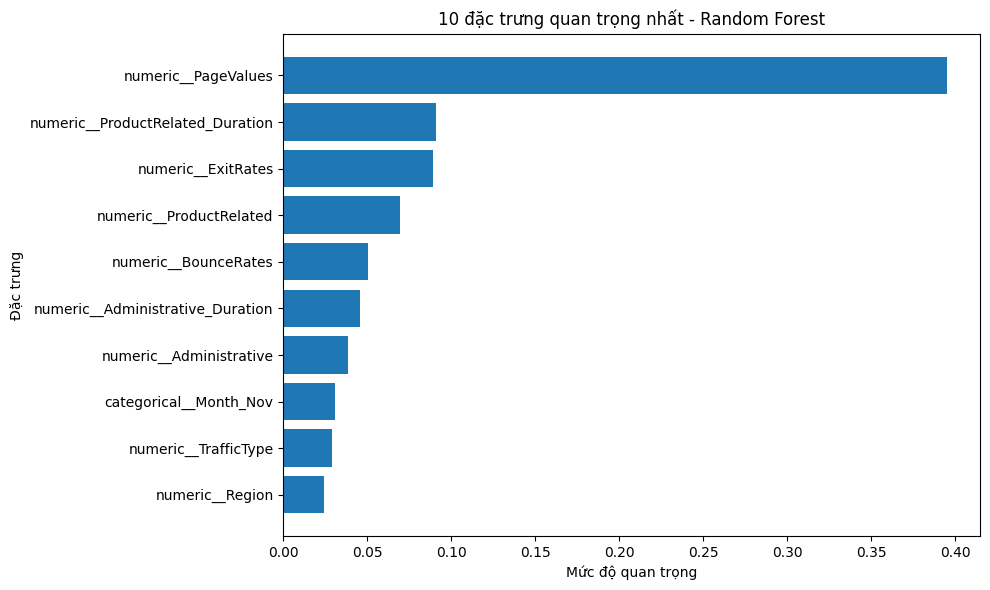

In [ ]:
# Vẽ 10 đặc trưng quan trọng nhất

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Mức độ quan trọng")
plt.ylabel("Đặc trưng")
plt.title("10 đặc trưng quan trọng nhất - Random Forest")

plt.tight_layout()
plt.show()

In [ ]:
# Lấy 3 đặc trưng quan trọng nhất

top_3_features = feature_importance.head(3).copy()

print("3 đặc trưng quan trọng nhất:")
print(top_3_features.to_string(index=False))

3 đặc trưng quan trọng nhất:
                         Feature  Importance
             numeric__PageValues    0.394862
numeric__ProductRelated_Duration    0.091159
              numeric__ExitRates    0.089385


In [ ]:
# Cài đặt thư viện SHAP
!pip install shap -q

In [ ]:
# Import thư viện SHAP
import shap

print("Đã cài đặt và import SHAP thành công!")

Đã cài đặt và import SHAP thành công!


In [ ]:
# Tạo SHAP Explainer cho mô hình Random Forest

explainer = shap.TreeExplainer(random_forest_model)

# Tính SHAP cho một phần dữ liệu Test
# Lấy tối đa 500 mẫu để chạy nhanh hơn
X_test_sample = X_test_processed[:500]

shap_values = explainer.shap_values(X_test_sample)

print("Đã tính SHAP thành công!")

Đã tính SHAP thành công!


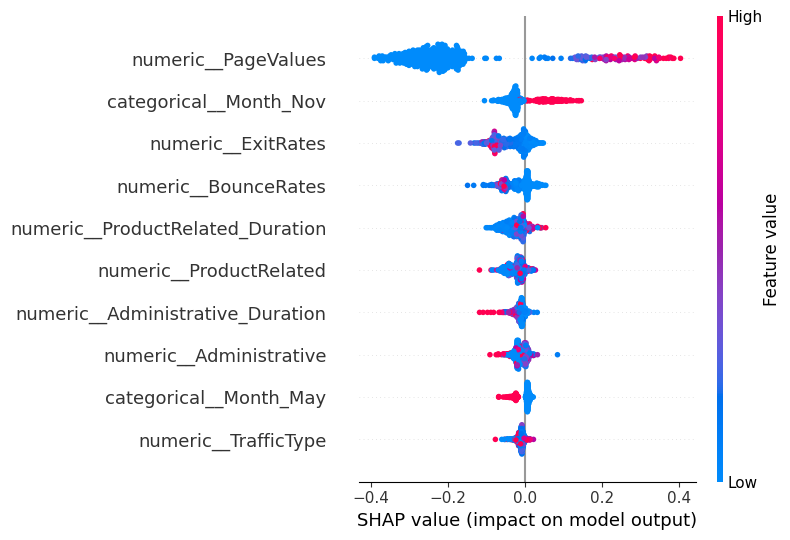

In [ ]:
# Vẽ biểu đồ SHAP tổng quan

shap.summary_plot(
    shap_values[:, :, 1],
    X_test_sample,
    feature_names=feature_names,
    max_display=10
)

In [ ]:
print(type(X_test_processed))
print(X_test_processed.shape)

<class 'numpy.ndarray'>
(2441, 28)


In [ ]:
# Kiểm tra tên 28 đặc trưng sau khi mã hóa
print("Số lượng đặc trưng:", len(preprocessor.get_feature_names_out()))

print("\nDanh sách đặc trưng:")
for i, feature in enumerate(preprocessor.get_feature_names_out(), start=1):
    print(i, "-", feature)

Số lượng đặc trưng: 28

Danh sách đặc trưng:
1 - categorical__Month_Aug
2 - categorical__Month_Dec
3 - categorical__Month_Feb
4 - categorical__Month_Jul
5 - categorical__Month_June
6 - categorical__Month_Mar
7 - categorical__Month_May
8 - categorical__Month_Nov
9 - categorical__Month_Oct
10 - categorical__Month_Sep
11 - categorical__VisitorType_New_Visitor
12 - categorical__VisitorType_Other
13 - categorical__VisitorType_Returning_Visitor
14 - numeric__Administrative
15 - numeric__Administrative_Duration
16 - numeric__Informational
17 - numeric__Informational_Duration
18 - numeric__ProductRelated
19 - numeric__ProductRelated_Duration
20 - numeric__BounceRates
21 - numeric__ExitRates
22 - numeric__PageValues
23 - numeric__SpecialDay
24 - numeric__OperatingSystems
25 - numeric__Browser
26 - numeric__Region
27 - numeric__TrafficType
28 - numeric__Weekend


In [ ]:
# ============================================================
# GIẢI THÍCH DỰ ĐOÁN CHO 1 KHÁCH HÀNG
# ============================================================

# Chọn khách hàng đầu tiên trong tập Test
customer_index = 0

# Lấy dữ liệu khách hàng
# X_test_processed là NumPy array nên dùng cách lấy này
customer_data = X_test_processed[customer_index:customer_index + 1]

# Lấy xác suất khách hàng mua hàng từ Random Forest
customer_probability = random_forest_model.predict_proba(
    customer_data
)[0][1]

# Ngưỡng quyết định đã tìm được ở bước trước
best_threshold_rf = 0.41

# Dự đoán dựa trên ngưỡng 0.41
customer_prediction = int(
    customer_probability >= best_threshold_rf
)

# ============================================================
# HIỂN THỊ KẾT QUẢ
# ============================================================

print("=" * 60)
print("KẾT QUẢ DỰ ĐOÁN KHÁCH HÀNG")
print("=" * 60)

print(
    "Xác suất mua hàng:",
    round(customer_probability * 100, 2),
    "%"
)

if customer_prediction == 1:
    print("Kết quả: CÓ khả năng mua hàng")
else:
    print("Kết quả: KHÔNG có khả năng mua hàng")


# ============================================================
# TÍNH MỨC ĐỘ ĐÓNG GÓP CỦA CÁC ĐẶC TRƯNG
# ============================================================

# Lấy SHAP của khách hàng đang xét
customer_shap = shap_values[1][customer_index]

# Lấy tên 28 đặc trưng
feature_names = preprocessor.get_feature_names_out()

# Tạo bảng giải thích
shap_customer_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP": customer_shap,
    "Value": customer_data[0]
})

# Mức độ đóng góp tuyệt đối
shap_customer_df["Abs_SHAP"] = (
    shap_customer_df["SHAP"].abs()
)

# Lấy 3 đặc trưng đóng góp nhiều nhất
top_3_features = (
    shap_customer_df
    .sort_values("Abs_SHAP", ascending=False)
    .head(3)
)

print("\n3 ĐẶC TRƯNG ĐÓNG GÓP CHÍNH:")
print(
    top_3_features[
        ["Feature", "SHAP", "Value"]
    ].to_string(index=False)
)

KẾT QUẢ DỰ ĐOÁN KHÁCH HÀNG
Xác suất mua hàng: 7.0 %
Kết quả: KHÔNG có khả năng mua hàng


ValueError: All arrays must be of the same length

In [ ]:
# Kiểm tra kích thước SHAP
print("Số tên đặc trưng:", len(feature_names))
print("Kích thước customer_shap:", np.array(customer_shap).shape)
print("Số giá trị customer_data:", len(customer_data[0]))

print("\nKiểu dữ liệu SHAP:")
print(type(shap_values))

print("\nKích thước shap_values:")
print(np.array(shap_values).shape)

Số tên đặc trưng: 28
Kích thước customer_shap: (2,)
Số giá trị customer_data: 28

Kiểu dữ liệu SHAP:
<class 'numpy.ndarray'>

Kích thước shap_values:
(500, 28, 2)


In [ ]:
# ============================================================
# GIẢI THÍCH DỰ ĐOÁN CHO 1 KHÁCH HÀNG
# ============================================================

# Chọn phiên truy cập đầu tiên trong tập Test
customer_index = 0

# Lấy dữ liệu của phiên truy cập
customer_data = X_test_processed[
    customer_index:customer_index + 1
]

# Lấy xác suất mua hàng
customer_probability = random_forest_model.predict_proba(
    customer_data
)[0][1]

# Ngưỡng quyết định của Random Forest
best_threshold_rf = 0.41

# Dự đoán
customer_prediction = int(
    customer_probability >= best_threshold_rf
)

print("=" * 60)
print("KẾT QUẢ DỰ ĐOÁN")
print("=" * 60)

print(
    "Xác suất mua hàng:",
    round(customer_probability * 100, 2),
    "%"
)

if customer_prediction == 1:
    print("Kết quả: CÓ khả năng mua hàng")
else:
    print("Kết quả: KHÔNG có khả năng mua hàng")


# ============================================================
# LẤY SHAP CHO LỚP "CÓ MUA"
# ============================================================

# shap_values có dạng:
# (số phiên, số đặc trưng, số lớp)
#
# [:, :, 1] = lấy SHAP của lớp True (có mua)

customer_shap = shap_values[
    customer_index, :, 1
]

# Lấy tên 28 đặc trưng
feature_names = preprocessor.get_feature_names_out()

# Tạo bảng giải thích
shap_customer_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP": customer_shap,
    "Value": customer_data[0]
})

# Tính độ lớn đóng góp
shap_customer_df["Abs_SHAP"] = (
    shap_customer_df["SHAP"].abs()
)

# Lấy 3 đặc trưng đóng góp mạnh nhất
top_3_features = (
    shap_customer_df
    .sort_values(
        "Abs_SHAP",
        ascending=False
    )
    .head(3)
)

print("\n3 ĐẶC TRƯNG ĐÓNG GÓP CHÍNH:")
print(
    top_3_features[
        ["Feature", "SHAP", "Value"]
    ].to_string(index=False)
)

KẾT QUẢ DỰ ĐOÁN
Xác suất mua hàng: 7.0 %
Kết quả: KHÔNG có khả năng mua hàng

3 ĐẶC TRƯNG ĐÓNG GÓP CHÍNH:
               Feature      SHAP Value
   numeric__PageValues -0.224092   0.0
categorical__Month_Nov  0.054064   1.0
    numeric__ExitRates -0.053838  0.04


In [ ]:
# ============================================================
# DEMO DỰ ĐOÁN MỘT PHIÊN TRUY CẬP MỚI
# ============================================================

# Tạo một phiên truy cập mẫu
new_session = {
    "Administrative": 2,
    "Administrative_Duration": 50,
    "Informational": 1,
    "Informational_Duration": 20,
    "ProductRelated": 30,
    "ProductRelated_Duration": 800,
    "BounceRates": 0.02,
    "ExitRates": 0.04,
    "PageValues": 20,
    "SpecialDay": 0.0,
    "Month": "Nov",
    "OperatingSystems": 2,
    "Browser": 2,
    "Region": 1,
    "TrafficType": 2,
    "VisitorType": "Returning_Visitor",
    "Weekend": False
}

# Chuyển dữ liệu thành DataFrame
new_session_df = pd.DataFrame([new_session])

print("Thông tin phiên truy cập mới:")
display(new_session_df)

Thông tin phiên truy cập mới:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,2,50,1,20,30,800,0.02,0.04,20,0.0,Nov,2,2,1,2,Returning_Visitor,False


In [ ]:
# Mã hóa phiên truy cập mới
new_session_processed = preprocessor.transform(new_session_df)

print(
    "Kích thước dữ liệu sau mã hóa:",
    new_session_processed.shape
)

Kích thước dữ liệu sau mã hóa: (1, 28)


In [ ]:
# ============================================================
# DỰ ĐOÁN XÁC SUẤT MUA HÀNG
# ============================================================

# Dự đoán xác suất bằng Random Forest
new_probability = random_forest_model.predict_proba(
    new_session_processed
)[0][1]

# Sử dụng ngưỡng 0.41 đã tìm được trên Validation
new_prediction = int(
    new_probability >= best_threshold_rf
)

print("=" * 60)
print("KẾT QUẢ DỰ ĐOÁN PHIÊN TRUY CẬP MỚI")
print("=" * 60)

print(
    "Xác suất mua hàng:",
    round(new_probability * 100, 2),
    "%"
)

print(
    "Ngưỡng quyết định:",
    best_threshold_rf
)

if new_prediction == 1:
    print("Dự đoán: CÓ khả năng mua hàng")
else:
    print("Dự đoán: KHÔNG có khả năng mua hàng")

KẾT QUẢ DỰ ĐOÁN PHIÊN TRUY CẬP MỚI
Xác suất mua hàng: 41.0 %
Ngưỡng quyết định: 0.41
Dự đoán: CÓ khả năng mua hàng


In [ ]:
# ============================================================
# GIẢI THÍCH DỰ ĐOÁN BẰNG SHAP
# ============================================================

# Tính SHAP cho phiên truy cập mới
new_shap_values = explainer.shap_values(
    new_session_processed
)

# Lấy SHAP của lớp True = Có mua
new_customer_shap = new_shap_values[0, :, 1]

# Lấy tên đặc trưng
feature_names = preprocessor.get_feature_names_out()

# Tạo bảng
new_shap_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP": new_customer_shap,
    "Value": new_session_processed[0]
})

# Độ lớn đóng góp
new_shap_df["Abs_SHAP"] = new_shap_df["SHAP"].abs()

# Lấy 3 đặc trưng đóng góp lớn nhất
top_3_new = (
    new_shap_df
    .sort_values("Abs_SHAP", ascending=False)
    .head(3)
)

print("3 ĐẶC TRƯNG ĐÓNG GÓP CHÍNH:")
display(
    top_3_new[
        ["Feature", "SHAP", "Value"]
    ]
)

3 ĐẶC TRƯNG ĐÓNG GÓP CHÍNH:


,Feature,SHAP,Value
21,numeric__PageValues,0.256248,20
20,numeric__ExitRates,-0.110234,0.04
19,numeric__BounceRates,-0.088861,0.02


In [ ]:
# ============================================================
# BẢNG TỔNG HỢP KẾT QUẢ 3 MÔ HÌNH
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Threshold": [
        threshold_lr,
        threshold_dt,
        threshold_rf
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_test_prob_lr),
        roc_auc_score(y_test, y_test_prob_dt),
        roc_auc_score(y_test, y_test_prob_rf)
    ],
    "F1": [
        f1_score(y_test, y_test_pred_lr),
        f1_score(y_test, y_test_pred_dt),
        f1_score(y_test, y_test_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_test_pred_lr),
        precision_score(y_test, y_test_pred_dt),
        precision_score(y_test, y_test_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_test_pred_lr),
        recall_score(y_test, y_test_pred_dt),
        recall_score(y_test, y_test_pred_rf)
    ]
})

results = results.round(4)

display(results)

,Model,Threshold,ROC-AUC,F1,Precision,Recall
0,Logistic Regression,0.5608,0.9171,0.6619,0.6034,0.7330
1,Decision Tree,1.0000,0.7400,0.5624,0.5646,0.5602
2,Random Forest,0.4100,0.9259,0.6640,0.6739,0.6545


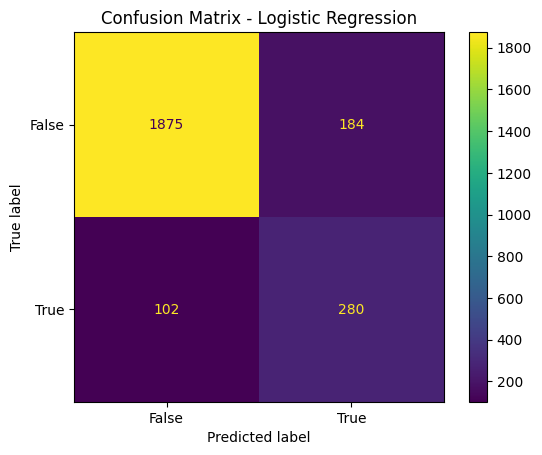

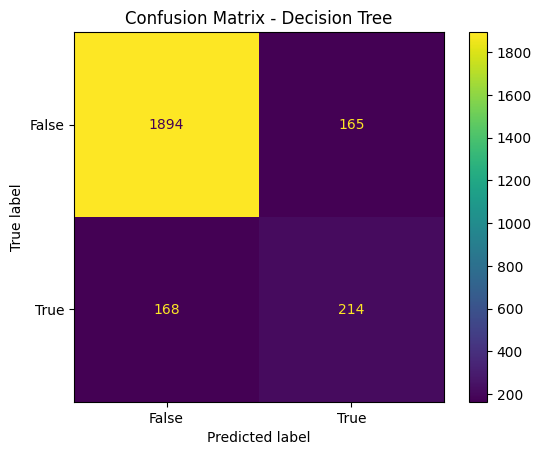

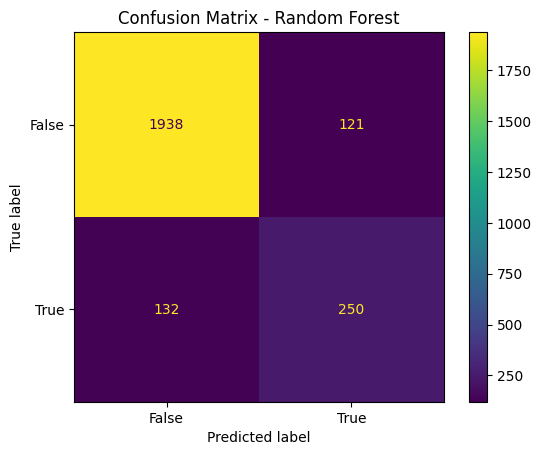

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# ==============================
# Confusion Matrix - 3 mô hình
# ==============================

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_lr
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()


# Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_dt
)

plt.title("Confusion Matrix - Decision Tree")
plt.show()


# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_rf
)

plt.title("Confusion Matrix - Random Forest")
plt.show()

In [ ]:
# ============================================================
# DEMO DỰ ĐOÁN KHẢ NĂNG MUA HÀNG
# ============================================================

# Nhập thông tin một phiên truy cập mới
new_session = {
    "Administrative": 2,
    "Administrative_Duration": 50,
    "Informational": 1,
    "Informational_Duration": 20,
    "ProductRelated": 30,
    "ProductRelated_Duration": 800,
    "BounceRates": 0.02,
    "ExitRates": 0.04,
    "PageValues": 20,
    "SpecialDay": 0.0,
    "Month": "Nov",
    "OperatingSystems": 2,
    "Browser": 2,
    "Region": 1,
    "TrafficType": 2,
    "VisitorType": "Returning_Visitor",
    "Weekend": False
}

# Chuyển thành DataFrame
new_session_df = pd.DataFrame([new_session])

# Tiền xử lý dữ liệu
new_session_processed = preprocessor.transform(
    new_session_df
)

# ============================================================
# DỰ ĐOÁN
# ============================================================

# Xác suất thuộc lớp "Có mua"
probability = random_forest_model.predict_proba(
    new_session_processed
)[0][1]

# Ngưỡng đã xác định trên Validation
threshold = 0.41

# Kết quả dự đoán
prediction = int(probability >= threshold)

print("=" * 60)
print("        DEMO DỰ ĐOÁN KHẢ NĂNG MUA HÀNG")
print("=" * 60)

print(f"Xác suất mua hàng: {probability * 100:.2f}%")
print(f"Ngưỡng quyết định: {threshold:.2f}")

if prediction == 1:
    print("Kết quả: CÓ khả năng mua hàng")
else:
    print("Kết quả: KHÔNG có khả năng mua hàng")


# ============================================================
# GIẢI THÍCH BẰNG SHAP
# ============================================================

# Tính SHAP cho phiên mới
new_shap_values = explainer.shap_values(
    new_session_processed
)

# Lấy SHAP của lớp "Có mua"
new_shap = new_shap_values[0, :, 1]

# Tên các đặc trưng
feature_names = preprocessor.get_feature_names_out()

# Tạo bảng
explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP": new_shap,
    "Value": new_session_processed[0]
})

# Độ lớn đóng góp
explanation["Abs_SHAP"] = explanation["SHAP"].abs()

# Lấy 3 đặc trưng đóng góp lớn nhất
top_3 = (
    explanation
    .sort_values("Abs_SHAP", ascending=False)
    .head(3)
)

print("\n3 ĐẶC TRƯNG ĐÓNG GÓP CHÍNH:")

for _, row in top_3.iterrows():

    direction = (
        "tăng khả năng mua"
        if row["SHAP"] > 0
        else "giảm khả năng mua"
    )

    print(
        f"- {row['Feature']}: "
        f"SHAP = {row['SHAP']:.4f} → {direction}"
    )

        DEMO DỰ ĐOÁN KHẢ NĂNG MUA HÀNG
Xác suất mua hàng: 41.00%
Ngưỡng quyết định: 0.41
Kết quả: CÓ khả năng mua hàng

3 ĐẶC TRƯNG ĐÓNG GÓP CHÍNH:
- numeric__PageValues: SHAP = 0.2562 → tăng khả năng mua
- numeric__ExitRates: SHAP = -0.1102 → giảm khả năng mua
- numeric__BounceRates: SHAP = -0.0889 → giảm khả năng mua


In [ ]:
print("Số lượng đặc trưng:", len(new_session))
print("\nTên các đặc trưng:")

for feature in new_session:
    print("-", feature)

Số lượng đặc trưng: 17

Tên các đặc trưng:
- Administrative
- Administrative_Duration
- Informational
- Informational_Duration
- ProductRelated
- ProductRelated_Duration
- BounceRates
- ExitRates
- PageValues
- SpecialDay
- Month
- OperatingSystems
- Browser
- Region
- TrafficType
- VisitorType
- Weekend
